In [1]:
import pandas as pd
from pathlib import Path

data_path = Path("..") / "Day48" / "cleaned_customer_data.csv"

df = pd.read_csv(data_path)

print("Day 50 - Model Optimization")
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Columns:", df.columns.tolist())

Day 50 - Model Optimization
Dataset shape: (51290, 28)
Missing values: 0
Columns: ['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_name', 'segment', 'state', 'country', 'market', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'shipping_cost', 'order_priority', 'year', 'shipping_days', 'profit_margin', 'order_month', 'order_day', 'order_day_of_week', 'sales_category', 'profit_status']


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Select features available before the outcome is known
features = [
    "segment",
    "ship_mode",
    "category",
    "sub_category",
    "region",
    "market",
    "order_priority",
    "quantity",
    "discount",
    "shipping_cost",
    "shipping_days",
    "order_month"
]

X = df[features].copy()
y = df["profit_status"]

# Encode categorical features
X = pd.get_dummies(X, drop_first=True)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("\nTarget classes:")
print(y.value_counts())

Training rows: 41032
Testing rows: 10258
Number of features: 49

Target classes:
profit_status
Profit        38079
Loss          12543
Break-even      668
Name: count, dtype: int64


Baseline Decision Tree Results
Accuracy: 87.66 %

Classification Report:
              precision    recall  f1-score   support

  Break-even       0.05      0.07      0.06       133
        Loss       0.80      0.80      0.80      2509
      Profit       0.92      0.92      0.92      7616

    accuracy                           0.88     10258
   macro avg       0.59      0.59      0.59     10258
weighted avg       0.88      0.88      0.88     10258



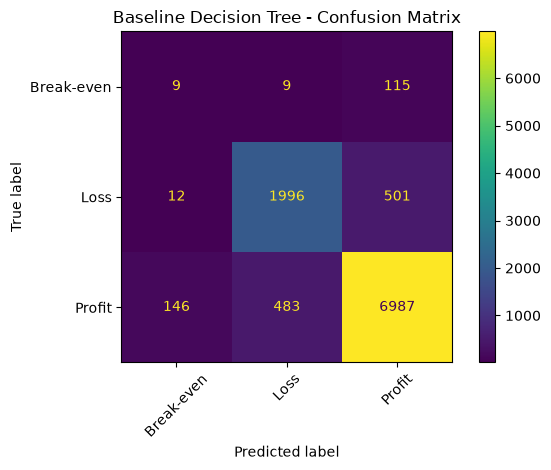

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

baseline_model = DecisionTreeClassifier(random_state=42)

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, y_pred)

print("Baseline Decision Tree Results")
print("Accuracy:", round(baseline_accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45
)
plt.title("Baseline Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

In [4]:
print("Baseline Model Accuracy:", round(baseline_accuracy * 100, 2), "%")
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Baseline Model Accuracy: 87.66 %

Detailed Classification Report:
              precision    recall  f1-score   support

  Break-even       0.05      0.07      0.06       133
        Loss       0.80      0.80      0.80      2509
      Profit       0.92      0.92      0.92      7616

    accuracy                           0.88     10258
   macro avg       0.59      0.59      0.59     10258
weighted avg       0.88      0.88      0.88     10258



In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

param_grid = {
    "max_depth": [5, 10, 15, 20],
    "min_samples_split": [2, 10, 20],
    "min_samples_leaf": [1, 5, 10],
    "class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

optimized_model = grid_search.best_estimator_
optimized_pred = optimized_model.predict(X_test)

optimized_accuracy = accuracy_score(y_test, optimized_pred)

print("Best Parameters:", grid_search.best_params_)
print("Optimized Accuracy:", round(optimized_accuracy * 100, 2), "%")
print("\nOptimized Classification Report:")
print(classification_report(
    y_test,
    optimized_pred,
    zero_division=0
))

Best Parameters: {'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Optimized Accuracy: 91.89 %

Optimized Classification Report:
              precision    recall  f1-score   support

  Break-even       0.00      0.00      0.00       133
        Loss       0.91      0.79      0.85      2509
      Profit       0.92      0.98      0.95      7616

    accuracy                           0.92     10258
   macro avg       0.61      0.59      0.60     10258
weighted avg       0.91      0.92      0.91     10258



In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)
rf_pred = random_forest.predict(X_test)

comparison = pd.DataFrame({
    "Model": [
        "Baseline Decision Tree",
        "Optimized Decision Tree",
        "Random Forest"
    ],
    "Accuracy (%)": [
        accuracy_score(y_test, y_pred) * 100,
        accuracy_score(y_test, optimized_pred) * 100,
        accuracy_score(y_test, rf_pred) * 100
    ],
    "Macro F1-score": [
        f1_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, optimized_pred, average="macro", zero_division=0),
        f1_score(y_test, rf_pred, average="macro", zero_division=0)
    ]
})

print(comparison.round(4).to_string(index=False))

                  Model  Accuracy (%)  Macro F1-score
 Baseline Decision Tree       87.6584          0.5924
Optimized Decision Tree       91.8893          0.5989
          Random Forest       63.3847          0.5238


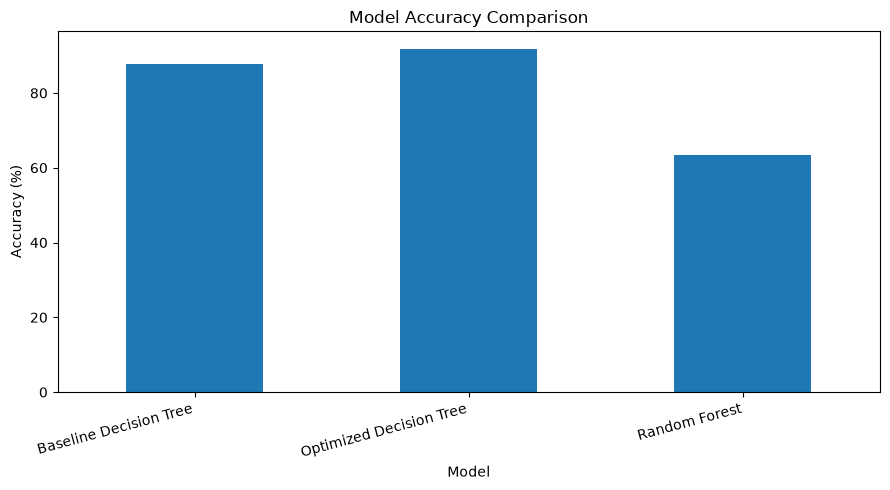

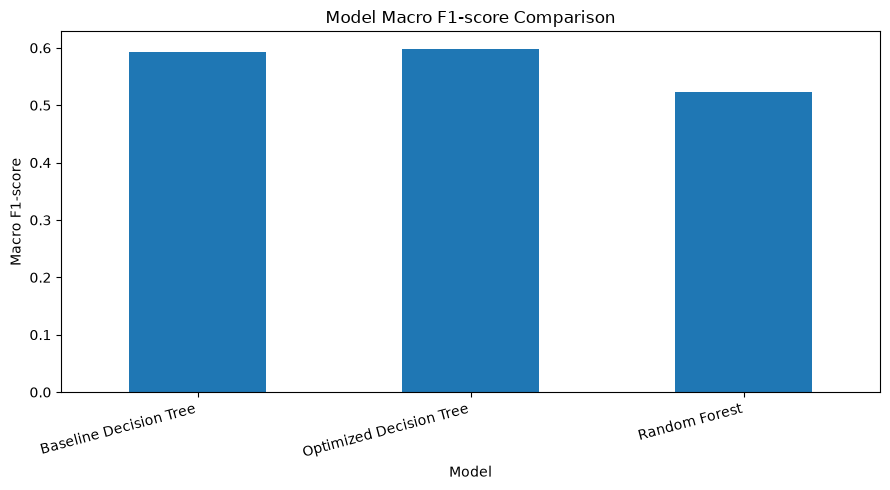

In [7]:
import matplotlib.pyplot as plt

comparison.set_index("Model")[["Accuracy (%)"]].plot(
    kind="bar",
    figsize=(9, 5),
    legend=False
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

comparison.set_index("Model")[["Macro F1-score"]].plot(
    kind="bar",
    figsize=(9, 5),
    legend=False
)

plt.title("Model Macro F1-score Comparison")
plt.ylabel("Macro F1-score")
plt.xlabel("Model")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import accuracy_score, f1_score

train_pred = optimized_model.predict(X_train)
test_pred = optimized_model.predict(X_test)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

train_f1 = f1_score(y_train, train_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_test, test_pred, average="macro", zero_division=0)

print("Optimized Decision Tree - Generalization Check")
print("-" * 45)
print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Testing Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Training Macro F1: {train_f1:.4f}")
print(f"Testing Macro F1:  {test_f1:.4f}")
print(f"Accuracy Gap:      {(train_accuracy - test_accuracy) * 100:.2f} percentage points")

Optimized Decision Tree - Generalization Check
---------------------------------------------
Training Accuracy: 92.13%
Testing Accuracy:  91.89%
Training Macro F1: 0.6040
Testing Macro F1:  0.5989
Accuracy Gap:      0.24 percentage points


In [9]:
comparison.to_csv(
    "../Day50/model_comparison.csv",
    index=False
)

performance_summary = pd.DataFrame({
    "Metric": [
        "Baseline Accuracy (%)",
        "Optimized Accuracy (%)",
        "Accuracy Improvement (percentage points)",
        "Training Accuracy (%)",
        "Testing Accuracy (%)",
        "Accuracy Gap (percentage points)"
    ],
    "Value": [
        accuracy_score(y_test, y_pred) * 100,
        accuracy_score(y_test, optimized_pred) * 100,
        (accuracy_score(y_test, optimized_pred) -
         accuracy_score(y_test, y_pred)) * 100,
        train_accuracy * 100,
        test_accuracy * 100,
        (train_accuracy - test_accuracy) * 100
    ]
})

performance_summary.to_csv(
    "../Day50/performance_summary.csv",
    index=False
)

print("Model comparison and performance results saved successfully!")

Model comparison and performance results saved successfully!


In [10]:
import joblib
from pathlib import Path

model_path = Path("../Day50/optimized_decision_tree.joblib")

joblib.dump(optimized_model, model_path)

print("Optimized model saved successfully!")
print("Model path:", model_path.resolve())

Optimized model saved successfully!
Model path: C:\Users\arjun\OneDrive\Desktop\ABTalks\Day50\optimized_decision_tree.joblib


In [12]:
print(comparison.columns.tolist())

['Model', 'Accuracy (%)', 'Macro F1-score']


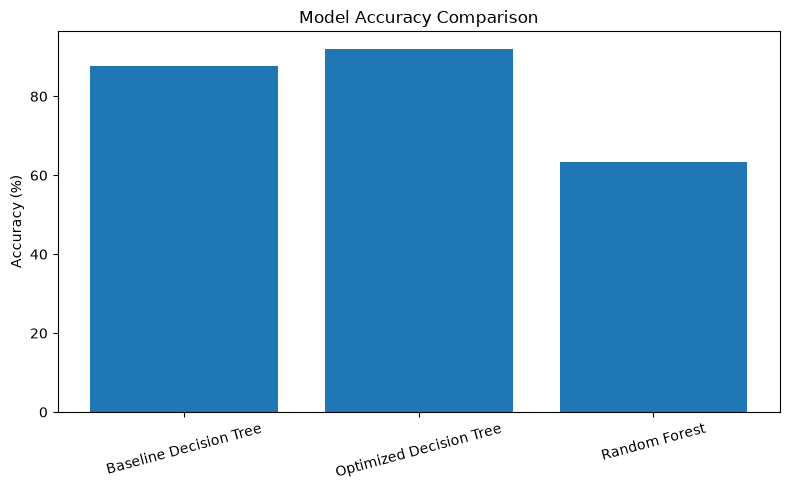

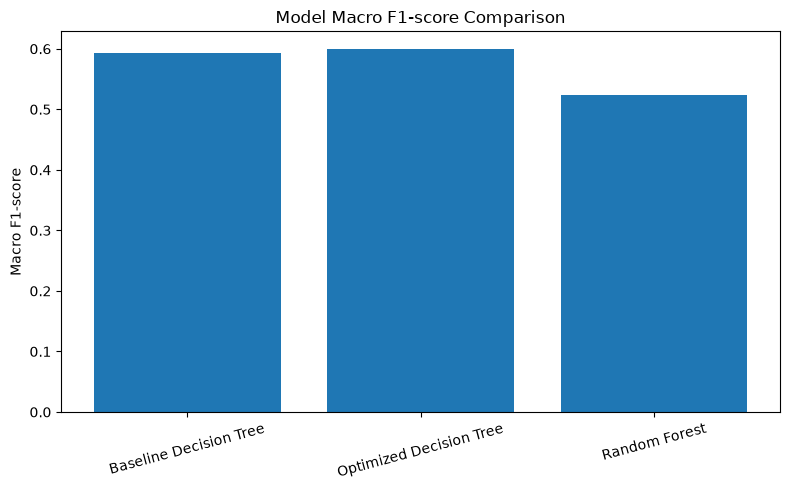

Performance graphs saved successfully!


In [14]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path("../Day50")
output_dir.mkdir(exist_ok=True)

plt.figure(figsize=(8, 5))
plt.bar(comparison["Model"], comparison["Accuracy (%)"])
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(output_dir / "model_accuracy_comparison.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(comparison["Model"], comparison["Macro F1-score"])
plt.title("Model Macro F1-score Comparison")
plt.ylabel("Macro F1-score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(output_dir / "model_f1_comparison.png", dpi=300)
plt.show()

print("Performance graphs saved successfully!")